# 02 GoEmotions DistilBERT
Problem Statement: Fine-tune a pretrained DistilBERT Transformer to perform multi-label emotion classification on short English Reddit comments, predicting any applicable emotion category from 27 emotions plus neutral.
Methodology:
- Load the simplified GoEmotions configuration.
- Convert labels to 28-dimensional multi-hot vectors.
- Fine-tune `distilbert-base-uncased` using `BCEWithLogitsLoss`.
- Tune global/per-label thresholds on the validation set, and evaluate on the test set.

In [1]:
from google.colab import drive
from pathlib import Path
from datasets import load_dataset
import json

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/NLP_Lab')
PROCESSED_DIR = ROOT / 'processed_data/go_emotions'
CKPT_DIR = ROOT / 'checkpoints/distilbert_goemotions'

# Verify Notebook 00 Artifacts
expected_files = [
    PROCESSED_DIR / 'goemotions_schema.json',
    PROCESSED_DIR / 'goemotions_data_quality.json'
]
print("--- Notebook 00 Artifact Verification ---")
for f in expected_files:
    print(f"{f.name:30} | {'FOUND' if f.exists() else 'MISSING'}")

print("\n--- Loading GoEmotions Dataset ---")
emotion_ds = load_dataset("google-research-datasets/go_emotions", "simplified")
print(emotion_ds)

# Extract and save label mapping
features = emotion_ds["train"].features
labels_list = features['labels'].feature.names

id2label = {str(i): label for i, label in enumerate(labels_list)}
label2id = {label: i for i, label in enumerate(labels_list)}

with open(PROCESSED_DIR / 'goemotions_label_mapping.json', 'w') as f:
    json.dump({"id2label": id2label, "label2id": label2id}, f, indent=2)

print(f"Loaded {len(labels_list)} labels. Mapping saved.")

Mounted at /content/drive
--- Notebook 00 Artifact Verification ---
goemotions_schema.json         | FOUND
goemotions_data_quality.json   | FOUND

--- Loading GoEmotions Dataset ---


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

... (3 outputs left out)

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})
Loaded 28 labels. Mapping saved.


In [2]:
import numpy as np

print("--- Preparing Multi-Hot Vectors ---")
num_labels = len(labels_list)

def add_multihot_labels(example):
    # Create a zero vector of length 28
    multi_hot = np.zeros(num_labels, dtype=np.float32)
    # Set 1.0 at the indices present in the 'labels' list
    for label_idx in example['labels']:
        multi_hot[label_idx] = 1.0
    example['multi_hot'] = multi_hot
    return example

# Apply to all splits
encoded_ds = emotion_ds.map(add_multihot_labels)

print("\nVerification of Sample 0 (Train):")
print("Original Text:", encoded_ds['train'][0]['text'])
print("Original Labels:", encoded_ds['train'][0]['labels'])
print("Mapped Emotion Names:", [id2label[str(idx)] for idx in encoded_ds['train'][0]['labels']])
print("Multi-Hot Vector Shape:", np.array(encoded_ds['train'][0]['multi_hot']).shape)
print("Multi-Hot Non-Zero Indices:", np.where(np.array(encoded_ds['train'][0]['multi_hot']) == 1.0)[0].tolist())

# Assertions to strictly enforce the specification
assert np.array(encoded_ds['train'][0]['multi_hot']).shape[0] == 28, "FAIL: Vector is not length 28."
assert encoded_ds['train'][0]['multi_hot'][27] == 1.0, "FAIL: Multi-hot mapping failed."
print("\nSTATUS: PASS. Multi-hot vectors generated correctly.")

--- Preparing Multi-Hot Vectors ---


Map:   0%|          | 0/43410 [00:00<?, ? examples/s]

Map:   0%|          | 0/5426 [00:00<?, ? examples/s]

Map:   0%|          | 0/5427 [00:00<?, ? examples/s]


Verification of Sample 0 (Train):
Original Text: My favourite food is anything I didn't have to cook myself.
Original Labels: [27]
Mapped Emotion Names: ['neutral']
Multi-Hot Vector Shape: (28,)
Multi-Hot Non-Zero Indices: [27]

STATUS: PASS. Multi-hot vectors generated correctly.


--- Tokenization & Length Audit ---


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/43410 [00:00<?, ? examples/s]

Map:   0%|          | 0/5426 [00:00<?, ? examples/s]

Map:   0%|          | 0/5427 [00:00<?, ? examples/s]

Mean token length: 19.17
95th percentile: 34.00
99th percentile: 38.00
Max token length: 316
Examples exceeding max_length=128: 1 (0.00%)
Token length plot saved to goemotions_token_length_dist.png


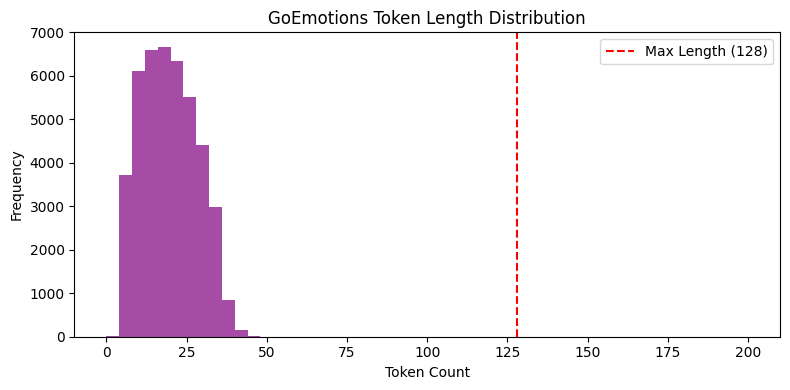

In [3]:
from transformers import AutoTokenizer
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("--- Tokenization & Length Audit ---")
tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")

# Tokenize a sample to check length distribution
def get_token_lengths(batch):
    tokens = tokenizer(batch['text'], truncation=False, return_attention_mask=False)
    return {'length': [len(ids) for ids in tokens['input_ids']]}

token_lens = emotion_ds.map(get_token_lengths, batched=True, remove_columns=emotion_ds['train'].column_names)

train_lengths = token_lens['train']['length']
print(f"Mean token length: {np.mean(train_lengths):.2f}")
print(f"95th percentile: {np.percentile(train_lengths, 95):.2f}")
print(f"99th percentile: {np.percentile(train_lengths, 99):.2f}")
print(f"Max token length: {np.max(train_lengths)}")

# Check truncation percentage at max_length = 128
max_len = 128
truncated_count = sum(1 for l in train_lengths if l > max_len)
print(f"Examples exceeding max_length={max_len}: {truncated_count} ({truncated_count/len(train_lengths)*100:.2f}%)")

# Save token length histogram
plt.figure(figsize=(8, 4))
plt.hist(train_lengths, bins=50, range=(0, 200), color='purple', alpha=0.7)
plt.axvline(x=max_len, color='red', linestyle='--', label=f'Max Length ({max_len})')
plt.title('GoEmotions Token Length Distribution')
plt.xlabel('Token Count')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
fig_path = ROOT / 'reports/figures/goemotions_token_length_dist.png'
plt.savefig(fig_path)
print(f"Token length plot saved to {fig_path.name}")

In [4]:
import torch
from torch.utils.data import DataLoader

def tokenize_and_format(batch):
    encoded = tokenizer(
        batch['text'],
        padding='max_length',
        truncation=True,
        max_length=128,
        return_tensors='pt'
    )
    encoded['labels'] = torch.tensor(batch['multi_hot'], dtype=torch.float)
    return encoded

print("--- Applying Tokenization Map ---")
tokenized_ds = encoded_ds.map(
    tokenize_and_format,
    batched=True,
    remove_columns=['text', 'id', 'labels', 'multi_hot']
)

# Set format for PyTorch
tokenized_ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])

batch_size = 16 # Safe for T4 GPU memory
train_loader = DataLoader(tokenized_ds['train'], batch_size=batch_size, shuffle=True)
val_loader = DataLoader(tokenized_ds['validation'], batch_size=batch_size, shuffle=False)
test_loader = DataLoader(tokenized_ds['test'], batch_size=batch_size, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

--- Applying Tokenization Map ---


Map:   0%|          | 0/43410 [00:00<?, ? examples/s]

Map:   0%|          | 0/5426 [00:00<?, ? examples/s]

Map:   0%|          | 0/5427 [00:00<?, ? examples/s]

Train batches: 2714
Validation batches: 340
Test batches: 340


In [5]:
from transformers import AutoModelForSequenceClassification
import json

print("--- Loading Pretrained DistilBERT ---")
with open(PROCESSED_DIR / 'goemotions_label_mapping.json', 'r') as f:
    mapping = json.load(f)

id2label = {int(k): v for k, v in mapping['id2label'].items()}
label2id = mapping['label2id']

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=28,
    problem_type="multi_label_classification",
    id2label=id2label,
    label2id=label2id
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Parameter count check
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

# Forward pass verification shape check
sample_batch = next(iter(train_loader))
input_ids = sample_batch['input_ids'].to(device)
attention_mask = sample_batch['attention_mask'].to(device)
labels = sample_batch['labels'].to(device)

outputs = model(input_ids=input_ids, attention_mask=attention_mask)
print(f"Logits output shape: {outputs.logits.shape}")

assert outputs.logits.shape == (batch_size, 28), "FAIL: Output logits shape mismatch."
print("STATUS: PASS. DistilBERT loaded and forward pass verified.")

--- Loading Pretrained DistilBERT ---


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total Parameters: 66,975,004
Trainable Parameters: 66,975,004
Logits output shape: torch.Size([16, 28])
STATUS: PASS. DistilBERT loaded and forward pass verified.


In [7]:
import torch.optim as optim
import time
from sklearn.metrics import f1_score
import json

print("--- Fine-Tuning DistilBERT on GoEmotions ---")
optimizer = optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
epochs = 3
best_val_f1 = 0.0

for epoch in range(epochs):
    start_time = time.time()
    model.train()
    total_train_loss = 0.0

    for batch in train_loader:
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        # Explicitly cast labels to float
        labels = batch['labels'].to(device).float()

        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # Validation Evaluation (Default threshold 0.5 for monitoring)
    model.eval()
    total_val_loss = 0.0
    all_preds, all_targets = [], []

    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            # Explicitly cast labels to float
            labels = batch['labels'].to(device).float()

            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            total_val_loss += outputs.loss.item()

            probs = torch.sigmoid(outputs.logits)
            preds = (probs >= 0.5).int().cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)
    val_macro_f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)
    val_micro_f1 = f1_score(all_targets, all_preds, average='micro', zero_division=0)

    epoch_time = time.time() - start_time
    print(f"Epoch {epoch+1}/{epochs} | Time: {epoch_time:.0f}s")
    print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Macro-F1: {val_macro_f1:.4f} | Val Micro-F1: {val_micro_f1:.4f}")

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        CKPT_DIR = ROOT / 'checkpoints/distilbert_goemotions'
        CKPT_DIR.mkdir(parents=True, exist_ok=True)
        model.save_pretrained(CKPT_DIR)
        tokenizer.save_pretrained(CKPT_DIR)
        print(f"-> Saved new best DistilBERT checkpoint.")

print("Training complete.")

--- Fine-Tuning DistilBERT on GoEmotions ---
Epoch 1/3 | Time: 511s
Train Loss: 0.1196 | Val Loss: 0.0876 | Val Macro-F1: 0.2917 | Val Micro-F1: 0.5244


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

-> Saved new best DistilBERT checkpoint.
Epoch 2/3 | Time: 512s
Train Loss: 0.0828 | Val Loss: 0.0855 | Val Macro-F1: 0.4174 | Val Micro-F1: 0.5638


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

-> Saved new best DistilBERT checkpoint.
Epoch 3/3 | Time: 512s
Train Loss: 0.0715 | Val Loss: 0.0856 | Val Macro-F1: 0.4531 | Val Micro-F1: 0.5803


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

-> Saved new best DistilBERT checkpoint.
Training complete.


In [8]:
import torch
import numpy as np
from sklearn.metrics import f1_score

print("--- Threshold Tuning on Validation Set ---")
model.eval()

# Collect all validation probabilities and true labels
val_probs, val_targets = [], []
with torch.no_grad():
    for batch in val_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.sigmoid(outputs.logits)

        val_probs.extend(probs.cpu().numpy())
        val_targets.extend(labels.cpu().numpy())

val_probs = np.array(val_probs)
val_targets = np.array(val_targets)

# Search for the best global threshold between 0.1 and 0.9
best_threshold = 0.5
best_macro_f1 = 0.0

thresholds = np.linspace(0.1, 0.9, 9)
for th in thresholds:
    preds = (val_probs >= th).astype(int)
    score = f1_score(val_targets, preds, average='macro', zero_division=0)
    print(f"Threshold {th:.1f} | Val Macro-F1: {score:.4f}")
    if score > best_macro_f1:
        best_macro_f1 = score
        best_threshold = th

print(f"\nOptimal Global Threshold: {best_threshold:.2f} (Val Macro-F1: {best_macro_f1:.4f})")

# Save thresholds config
import json
with open(CKPT_DIR / 'thresholds.json', 'w') as f:
    json.dump({"global_threshold": float(best_threshold), "best_val_macro_f1": float(best_macro_f1)}, f, indent=2)

--- Threshold Tuning on Validation Set ---
Threshold 0.1 | Val Macro-F1: 0.4596
Threshold 0.2 | Val Macro-F1: 0.4946
Threshold 0.3 | Val Macro-F1: 0.4960
Threshold 0.4 | Val Macro-F1: 0.4809
Threshold 0.5 | Val Macro-F1: 0.4531
Threshold 0.6 | Val Macro-F1: 0.4092
Threshold 0.7 | Val Macro-F1: 0.3748
Threshold 0.8 | Val Macro-F1: 0.3062
Threshold 0.9 | Val Macro-F1: 0.1751

Optimal Global Threshold: 0.30 (Val Macro-F1: 0.4960)


In [9]:
from sklearn.metrics import classification_report, hamming_loss, accuracy_score
import pandas as pd

print("--- Evaluating on Held-Out Test Set ---")
test_probs, test_targets = [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.sigmoid(outputs.logits)

        test_probs.extend(probs.cpu().numpy())
        test_targets.extend(labels.cpu().numpy())

test_probs = np.array(test_probs)
test_targets = np.array(test_targets)

# Apply optimal threshold found on validation
test_preds = (test_probs >= best_threshold).astype(int)

test_macro_f1 = f1_score(test_targets, test_preds, average='macro', zero_division=0)
test_micro_f1 = f1_score(test_targets, test_preds, average='micro', zero_division=0)
h_loss = hamming_loss(test_targets, test_preds)
subset_acc = accuracy_score(test_targets, test_preds)

print(f"Test Macro-F1: {test_macro_f1:.4f}")
print(f"Test Micro-F1: {test_micro_f1:.4f}")
print(f"Hamming Loss: {h_loss:.4f}")
print(f"Subset Accuracy (Exact Match): {subset_acc:.4f}")

# Per-label classification report
target_names = [id2label[i] for i in range(28)]
report = classification_report(test_targets, test_preds, target_names=target_names, output_dict=True, zero_division=0)
print("\n--- Per-Label Summary Preview ---")
print(classification_report(test_targets, test_preds, target_names=target_names, zero_division=0))

# Save metrics
metrics_bundle = {
    "test_macro_f1": float(test_macro_f1),
    "test_micro_f1": float(test_micro_f1),
    "hamming_loss": float(h_loss),
    "subset_accuracy": float(subset_acc),
    "optimal_threshold": float(best_threshold),
    "per_label_report": report
}

with open(CKPT_DIR / 'final_test_metrics.json', 'w') as f:
    json.dump(metrics_bundle, f, indent=2)

--- Evaluating on Held-Out Test Set ---
Test Macro-F1: 0.4839
Test Micro-F1: 0.5917
Hamming Loss: 0.0361
Subset Accuracy (Exact Match): 0.4183

--- Per-Label Summary Preview ---
                precision    recall  f1-score   support

    admiration       0.58      0.83      0.68       504
     amusement       0.77      0.87      0.82       264
         anger       0.45      0.51      0.48       198
     annoyance       0.34      0.38      0.36       320
      approval       0.43      0.34      0.38       351
        caring       0.56      0.33      0.42       135
     confusion       0.34      0.61      0.44       153
     curiosity       0.46      0.72      0.56       284
        desire       0.63      0.45      0.52        83
disappointment       0.33      0.30      0.31       151
   disapproval       0.35      0.52      0.42       267
       disgust       0.50      0.53      0.52       123
 embarrassment       0.74      0.38      0.50        37
    excitement       0.38      0.50  

In [10]:
print("--- Notebook 02 Verification Gates ---")
expected_files = [
    CKPT_DIR / 'model.safetensors',
    CKPT_DIR / 'tokenizer_config.json',
    CKPT_DIR / 'thresholds.json',
    CKPT_DIR / 'final_test_metrics.json'
]

all_passed = True
for f in expected_files:
    status = 'PASS' if f.exists() and f.stat().st_size > 0 else 'FAIL'
    print(f"{f.name:30} | {status}")
    if status == 'FAIL':
        all_passed = False

if all_passed:
    print("\nSTATUS: PASS. Model B pipeline is complete and verified.")
else:
    print("\nSTATUS: FAIL. Missing artifacts.")

--- Notebook 02 Verification Gates ---
model.safetensors              | PASS
tokenizer_config.json          | PASS
thresholds.json                | PASS
final_test_metrics.json        | PASS

STATUS: PASS. Model B pipeline is complete and verified.
